# 画像処理 ― ndimage モジュール

## この章で学ぶこと

`scipy.ndimage` は、多次元の画像を処理する関数の集まりです。フィルタ、フーリエ変換、補間と回転、測定、形態学的な処理などのモジュールがあります。この章では、二値画像(白と黒だけの画像)を題材に、次の内容を確かめます。

* 膨張と収縮(`binary_dilation()`、`binary_erosion()`)
* 構造要素の決め方
* Hit と Miss 演算(`binary_hit_or_miss()`)
* 細線化
* 距離変換とラベリングで、接している領域を分ける

In [1]:
import helper.matplotlib
from matplotlib import pyplot as plt

import numpy as np

:::{admonition} より強力な画像処理ライブラリ
:class: seealso
`scipy.ndimage` にあるのは基本的な処理だけです。本格的な画像処理には、次のライブラリを使います。

* OpenCV：C/C++ で書かれたコンピュータビジョンのライブラリ。
* scikit-image：Python の画像処理ライブラリ。重い計算は Cython で書かれている。
:::

## 二値画像の形態学的処理

`morphology` モジュールで、二値画像を処理します。二値画像の各ピクセルは黒か白の 2 色だけです。NumPy では、2 次元のブール配列で表せます(`False` が黒、`True` が白)。`uint8` の配列でも表せて、0 が黒、0 以外が白です。

次の 2 つの関数は、処理の結果を見やすく表示するためのものです。

In [2]:
def expand_image(img, value, out=None, size=10):
    """ピクセルを size 倍に拡大し、value の色で塗る。"""
    if out is None:
        w, h = img.shape
        out = np.zeros((w * size, h * size), dtype=np.uint8)

    tmp = np.repeat(np.repeat(img, size, 0), size, 1)
    out[:, :] = np.where(tmp, value, out)
    out[::size, :] = 0      # 区切り線
    out[:, ::size] = 0
    return out


def show_image(*imgs):
    """複数の画像を横に並べて表示する。"""
    for idx, img in enumerate(imgs, 1):
        ax = plt.subplot(1, len(imgs), idx)
        plt.imshow(img, cmap="gray")
        ax.set_axis_off()
    plt.subplots_adjust(0.02, 0, 0.98, 1, 0.02, 0)
    plt.show()

### 膨張と収縮

二値画像の基本の演算は、膨張と収縮です。膨張は、白い領域に接している黒いピクセルを、白に変える処理です。言い換えると、各白ピクセルのまわりの黒ピクセルを白にします。

「まわり」の決め方は何通りもあります。次の図の左が元の画像、中が上下左右の 4 方向を「まわり」とした膨張、右が斜めも含めた 8 方向の膨張です。灰色の四角が、膨張で増えたピクセルです。

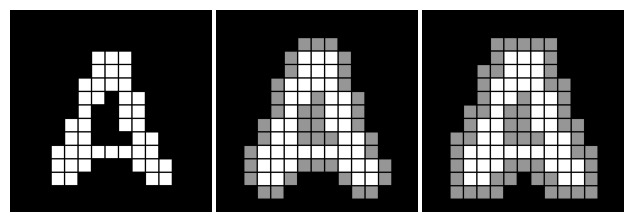

In [3]:
from scipy import ndimage


def dilation_demo(a, structure=None):
    """膨張して増えたピクセルを灰色で示す。"""
    b = ndimage.binary_dilation(a, structure)
    img = expand_image(a, 255)
    return expand_image(np.logical_xor(a, b), 150, out=img)


a = plt.imread("data/scipy_morphology_demo.png")[:, :, 0].astype(np.uint8)  # 元の二値画像
img1 = expand_image(a, 255)

img2 = dilation_demo(a)                          # 4 連結
img3 = dilation_demo(a, [[1, 1, 1], [1, 1, 1], [1, 1, 1]])  # 8 連結
show_image(img1, img2, img3)

4 連結は上下左右の 4 ピクセル、8 連結は斜めも入れた 8 ピクセルです。どちらも、次の行列で表せます。中心が処理するピクセルで、まわりの 1 と 0 が「まわり」に含めるかどうかを表します。この行列を構造要素(structuring element)と呼びます。

```text
四連結     八連結
0 1 0      1 1 1
1 1 1      1 1 1
0 1 0      1 1 1
```

`binary_dilation(a)` は、既定で 4 連結の膨張を行います。`structure` を渡すと、別の構造要素を使えます。8 連結なら次のとおりです。

```python
binary_dilation(a, structure=[[1,1,1],[1,1,1],[1,1,1]])
```

構造要素を変えると、結果も変わります。次の 3 つの構造要素で試します。

```text
 左       中      右
0 0 0   0 1 0   0 1 0
1 1 1   0 1 0   0 1 0
0 0 0   0 1 0   0 0 0
```

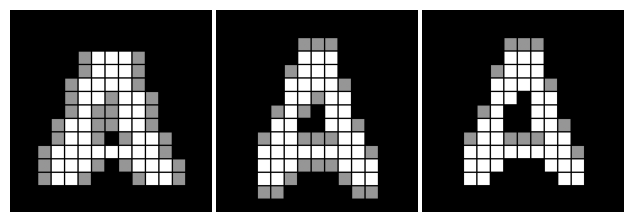

In [4]:
img4 = dilation_demo(a, [[0, 0, 0], [1, 1, 1], [0, 0, 0]])
img5 = dilation_demo(a, [[0, 1, 0], [0, 1, 0], [0, 1, 0]])
img6 = dilation_demo(a, [[0, 1, 0], [0, 1, 0], [0, 0, 0]])
show_image(img4, img5, img6)

`binary_erosion()` は収縮で、膨張の逆です。まわりに黒いピクセルがある白ピクセルを、黒に変えます。次の図は 4 連結と 8 連結の収縮で、灰色の四角が消えたピクセルです。

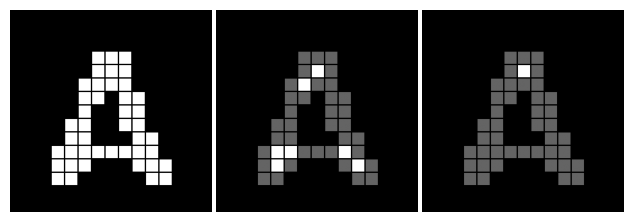

In [5]:
def erosion_demo(a, structure=None):
    """収縮して消えたピクセルを灰色で示す。"""
    b = ndimage.binary_erosion(a, structure)
    img = expand_image(a, 255)
    return expand_image(np.logical_xor(a, b), 100, out=img)


img1 = expand_image(a, 255)
img2 = erosion_demo(a)                          # 4 連結
img3 = erosion_demo(a, [[1, 1, 1], [1, 1, 1], [1, 1, 1]])  # 8 連結
show_image(img1, img2, img3)

### Hit と Miss

Hit と Miss は、二値の形態学的処理の基本になる演算です。ほとんどの処理は、この組み合わせで作れます。各ピクセルのまわりが決めたパターンに一致するかを見て、一致すれば白、しなければ黒にします。

白と黒の両方を見るので、構造要素を 2 つ渡します。呼び方は次のとおりです。

```python
binary_hit_or_miss(input, structure1=None, structure2=None, ...)
```

`structure1` が白のピクセルの構造要素、`structure2` が黒のピクセルの構造要素です。次の図の左が元の画像、中が次の 2 つの構造要素で計算した結果です。

```text
白い構造要素    黒い構造要素
  0 0 0          1 0 0
  0 1 0          0 0 0
  1 1 1          0 0 0
```

0 はその位置の色を問わない、1 は構造要素の色でなければならない、という意味です。この構造要素は「下の 3 つが白で、左上が黒の白ピクセル」を探します。

右の図は、次の構造要素で計算した結果です。「下の 3 つが白で、左上と中央が黒の黒ピクセル」を探します。

```text
  白い構造要素    黒い構造要素
    0 0 0          1 0 0
    0 0 0          0 1 0
    1 1 1          0 0 0
```

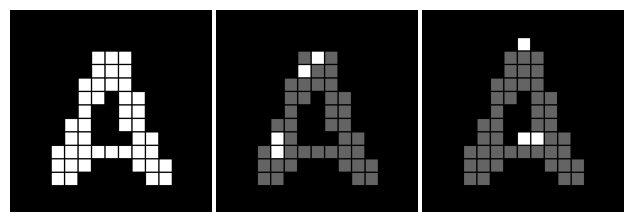

In [6]:
def hitmiss_demo(a, structure1, structure2):
    """Hit と Miss の結果を白で示す。"""
    b = ndimage.binary_hit_or_miss(a, structure1, structure2)
    img = expand_image(a, 100)
    return expand_image(b, 255, out=img)


img1 = expand_image(a, 255)

img2 = hitmiss_demo(
    a, [[0, 0, 0], [0, 1, 0], [1, 1, 1]], [[1, 0, 0], [0, 0, 0], [0, 0, 0]]
)
img3 = hitmiss_demo(
    a, [[0, 0, 0], [0, 0, 0], [1, 1, 1]], [[1, 0, 0], [0, 1, 0], [0, 0, 0]]
)

show_image(img1, img2, img3)

Hit と Miss を組み合わせると、複雑な処理も作れます。文字認識で使う細線化も、Hit と Miss の繰り返しでできます。細線化の結果は次の図で、プログラムはそのあとです。

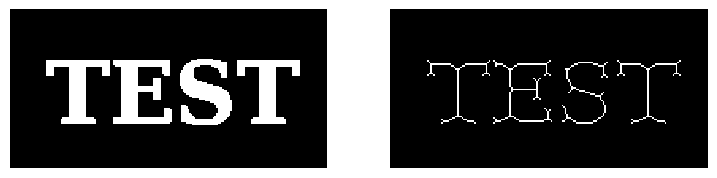

In [7]:
def skeletonize(img):
    """Hit と Miss を 8 方向から繰り返して、線を細くする。"""
    h1 = np.array([[0, 0, 0], [0, 1, 0], [1, 1, 1]])  #❶ 白の構造要素
    m1 = np.array([[1, 1, 1], [0, 0, 0], [0, 0, 0]])  #   黒の構造要素
    h2 = np.array([[0, 0, 0], [1, 1, 0], [0, 1, 0]])
    m2 = np.array([[0, 1, 1], [0, 0, 1], [0, 0, 0]])
    hit_list = []
    miss_list = []
    for k in range(4):  #❷ 90 度ずつ回して 8 通りにする
        hit_list.append(np.rot90(h1, k))
        hit_list.append(np.rot90(h2, k))
        miss_list.append(np.rot90(m1, k))
        miss_list.append(np.rot90(m2, k))
    img = img.copy()
    while True:
        last = img
        for hit, miss in zip(hit_list, miss_list):
            hm = ndimage.binary_hit_or_miss(img, hit, miss)  #❸ 端のピクセルを探す
            img = np.logical_and(img, np.logical_not(hm))  #❹ 見つかったピクセルを消す
        if np.all(img == last):  #❺ 変化がなければ終了
            break
    return img


a = plt.imread("data/scipy_morphology_demo2.png")[:, :, 0].astype(np.uint8)  # 細線化する画像
b = skeletonize(a)

_, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.imshow(a, cmap="gray", interpolation="nearest")
ax2.imshow(b, cmap="gray", interpolation="nearest")
ax1.set_axis_off()
ax2.set_axis_off()
plt.show()

❶ 図の 2 組の構造要素から、形状 `(3, 3)` の配列 `h1`、`m1`、`h2`、`m2` を作ります。`h1` と `m1` が左の組、`h2` と `m2` が右の組で、`h` が白、`m` が黒の構造要素です。❷ これらを 90 度ずつ回して、8 通りの構造要素にします。

❸ 8 通りを順に使って Hit と Miss を計算し、❹ 見つかった白いピクセルを画像から消します。これで、8 方向から端のピクセルを削れます。❺ 消えるピクセルがなくなるまで繰り返します。

![細線化アルゴリズムの4つの構造要素](images/scipy_image_skeletonization_01_large.png)

## 画像の分割

矩形の領域を見つける例で、`measurements` と `morphology` を使った領域の分割を説明します。対象の画像は次の図で、二値画像で、矩形が白、背景が黒です。JPEG で保存されているので、`pyplot.imread()` で読むと形状 `(高さ, 幅, 3)` の 3 チャンネルになります。次のプログラムは、第 0 チャンネルから二値配列 `squares` を作ります。矩形が 1、背景が 0 です。

In [8]:
squares = plt.imread("data/squares.jpg")
squares = (squares[:, :, 0] < 200).astype(np.uint8)

多くの矩形が、小さな突起で隣の矩形とつながっています。まず、これを切り離します。収縮でもできますが、ここでは距離変換を使います。

`morphology.distance_transform_cdt(image)` は、各ピクセルから最も近い黒ピクセルまでの距離を計算します。距離の定義はいくつもありますが、この関数は既定でチェビシェフ距離を使います。チェビシェフ距離は、座標の差のうち大きい方です。$D_{Chess} = \max \left ( \left | x_2 - x_1 \right | , \left | y_2 - y_1 \right | \right )$。

`squares_dt` が距離の配列です。図で赤いほど、黒い背景から遠いことを表します。白い領域の中心では、背景から 27 ピクセル離れています。

In [9]:
squares_dt = ndimage.distance_transform_cdt(squares)
print("各種距離値", np.unique(squares_dt))

各種距離値 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]


距離にしきい値を付けて二値にすると、矩形どうしを切り離せます。収縮したのと似た効果です。`squares_core` では、どの矩形も小さくなり、隣とつながっていません。

In [10]:
squares_core = (squares_dt > 8).astype(np.uint8)

次に、`measurements` の `label()` と `center_of_mass()` で、それぞれの白い領域に番号を振り、重心を計算します。

`label()` は、つながった白い領域ごとに整数を割り当てます。領域に「色」を付けるようなもので、ここでの色は整数の番号です。

`center_of_mass()` は、番号ごとの重心を返します。第 1 引数が各ピクセルの重み、第 2 引数が `label()` の結果、第 3 引数が重心を求める番号のリストです。重みと番号を同じにすると、白いピクセルの重心になります。

`label()` の結果をそのまま `imshow()` で表示すると、色が少しずつ変わる画像になり、領域が見分けにくくなります。そこで、`random_palette()` で番号ごとにランダムな色を割り当てます。

In [11]:
def random_palette(labels, count, seed=1):
    """番号ごとにランダムな色を割り当てる。"""
    np.random.seed(seed)
    palette = np.random.rand(count + 1, 3)
    palette[0, :] = 0
    return palette[labels]


labels, count = ndimage.label(squares_core)  # 領域に番号を振る
h, w = labels.shape
centers = np.array(
    ndimage.center_of_mass(labels, labels, index=range(1, count + 1)), np.int16
)
cores = random_palette(labels, count)

ここまでの結果では、各領域が元の画像より小さくなっています。これを元の大きさに戻します。元の画像で白く、収縮した画像で黒いピクセルを、いちばん近い領域の色にします。手順は次のとおりです。

❶ 収縮した画像 `squares_core` を反転して、`distance_transform_cdt()` を呼びます。これで、黒いピクセルに最も近い白いピクセルの座標が分かります。座標を得るには `return_indices=True`、距離は不要なので `return_distances=False` にします。戻り値 `index` は形状 `(2, 高さ, 幅)` で、`index[0]` が縦、`index[1]` が横の座標です。

❷ `index` で `labels` を引くと、近い領域の番号 `near_labels` が得られます。

❸ `squares` で白く、`squares_core` で黒いピクセルのマスク `mask` を作ります。`labels` を `labels2` にコピーし、`mask` の位置に `near_labels` の番号を入れます。

In [12]:
index = ndimage.distance_transform_cdt(
    1 - squares_core, return_distances=False, return_indices=True
)  #❶ 最も近い白ピクセルの座標
near_labels = labels[index[0], index[1]]  #❷ 近い領域の番号

mask = (squares - squares_core).astype(bool)
labels2 = labels.copy()
labels2[mask] = near_labels[mask]  #❸ 縮んだ分を元の大きさに戻す
separated = random_palette(labels2, count)

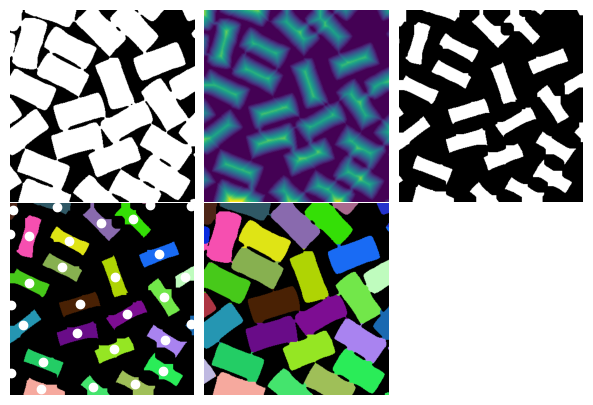

In [13]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(7.5, 5.0),
)
fig.delaxes(axes[1, 2])
axes[0, 0].imshow(squares, cmap="gray")
axes[0, 1].imshow(squares_dt)
axes[0, 2].imshow(squares_core, cmap="gray")
ax = axes[1, 0]
ax.imshow(cores)
center_y, center_x = centers.T
ax.plot(center_x, center_y, "o", color="white")
ax.set_xlim(0, w)
ax.set_ylim(h, 0)

axes[1, 1].imshow(separated)

for ax in axes.ravel():
    ax.axis("off")

fig.subplots_adjust(wspace=0.01, hspace=0.01)
plt.show()

## まとめ

* 二値画像は、`binary_dilation()` で膨らませ、`binary_erosion()` で痩せさせられる。`structure` で「まわり」の形を決める。
* Hit と Miss は、白と黒のパターンでピクセルを選ぶ基本の演算。組み合わせると細線化などが作れる。
* 距離変換 `distance_transform_cdt()` で、接している領域を切り離せる。
* `label()` で領域に番号を振り、`center_of_mass()` で重心を計算できる。
* 距離変換が返す座標を使うと、縮んだ領域を元の大きさに戻せる。